In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset produced in Phase 3
df = pd.read_csv("../electronics_analysis_ready.csv")

print("Dataset shape:", df.shape)

print("\nAvailable columns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

display(df.head())

Dataset shape: (5010, 17)

Available columns:
['name', 'main_category', 'sub_category', 'image', 'link', 'no_of_ratings', 'discount_price', 'actual_price', 'review_rating', 'review_text', 'discount_price_missing', 'actual_price_missing', 'review_count_missing', 'review_text_missing', 'price_available', 'discount_amount', 'discount_percent']

Data types:
name                       object
main_category              object
sub_category               object
image                      object
link                       object
no_of_ratings             float64
discount_price            float64
actual_price              float64
review_rating             float64
review_text                object
discount_price_missing      int64
actual_price_missing        int64
review_count_missing        int64
review_text_missing         int64
price_available             int64
discount_amount           float64
discount_percent          float64
dtype: object


,name,main_category,sub_category,image,link,no_of_ratings,discount_price,actual_price,review_rating,review_text,discount_price_missing,actual_price_missing,review_count_missing,review_text_missing,price_available,discount_amount,discount_percent
0,"redmi 10 power (power black, 8gb ram, 128gb st...","tv, audio & cameras",all electronics,https://m.media-amazon.com/images/I/81eM15lVcJ...,https://www.amazon.in/Redmi-Power-Black-128GB-...,965.0,10999.0,18999.0,3.0,NOTE:,0,0,0,0,1,8000.0,42.107479
1,"oneplus nord ce 2 lite 5g (blue tide, 6gb ram,...","tv, audio & cameras",all electronics,https://m.media-amazon.com/images/I/71AvQd3Vzq...,https://www.amazon.in/OnePlus-Nord-Lite-128GB-...,113956.0,18999.0,19999.0,1.0,Very bad experience with this device xr phone....,0,0,0,0,1,1000.0,5.000250
2,oneplus bullets z2 bluetooth wireless in ear e...,"tv, audio & cameras",all electronics,https://m.media-amazon.com/images/I/51UhwaQXCp...,https://www.amazon.in/Oneplus-Bluetooth-Wirele...,90304.0,1999.0,2299.0,5.0,Amazing phone with amazing camera coming from ...,0,0,0,0,1,300.0,13.049152
3,"samsung galaxy m33 5g (mystique green, 6gb, 12...","tv, audio & cameras",all electronics,https://m.media-amazon.com/images/I/81I3w4J6yj...,https://www.amazon.in/Samsung-Mystique-Storage...,24863.0,15999.0,24999.0,1.0,So I got the device XR just today. The product...,0,0,0,0,1,9000.0,36.001440
4,"oneplus nord ce 2 lite 5g (black dusk, 6gb ram...","tv, audio & cameras",all electronics,https://m.media-amazon.com/images/I/71V--WZVUI...,https://www.amazon.in/OnePlus-Nord-Black-128GB...,113956.0,18999.0,19999.0,5.0,I've been an android user all my life until I ...,0,0,0,0,1,1000.0,5.000250


PRODUCT CATEGORY DISTRIBUTION


,Product Count
product_category,
Other / Unclassified,1947
Smartphones,905
Headphones and Earphones,402
Laptops,395
Chargers and Cables,296
Smartwatches,263
Computer Accessories,197
Speakers,149
Cameras,146



Total classified products: 5010
Unclassified products: 1947


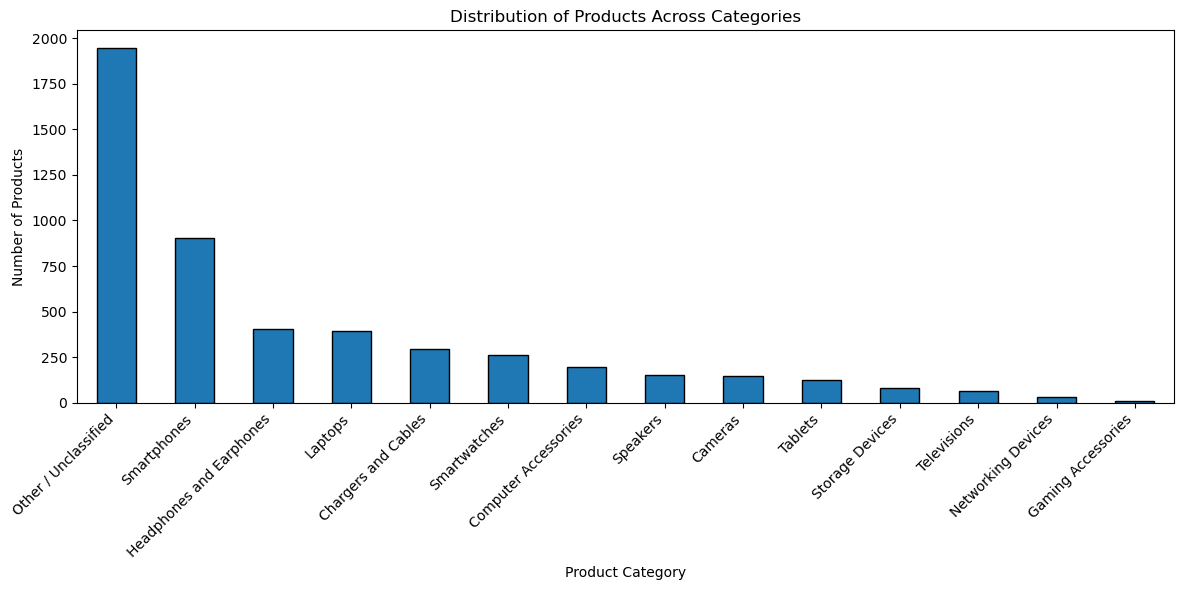

In [2]:
import re

def classify_product(title):
    title = str(title).lower()

    patterns = {
        "Smartphones": r"\b(smartphone|mobile phone|iphone|redmi|oneplus|samsung galaxy|realme narzo)\b",
        "Laptops": r"\b(laptop|macbook|notebook computer)\b",
        "Tablets": r"\b(tablet|ipad)\b",
        "Headphones and Earphones": r"\b(headphone|earphone|earbuds|airpods|neckband)\b",
        "Smartwatches": r"\b(smartwatch|smart watch|fitness band)\b",
        "Speakers": r"\b(speaker|soundbar|home theatre)\b",
        "Storage Devices": r"\b(ssd|hard disk|pendrive|memory card|external drive)\b",
        "Computer Accessories": r"\b(mouse|keyboard|laptop bag|mouse pad|laptop stand)\b",
        "Chargers and Cables": r"\b(charger|charging cable|usb cable|adapter)\b",
        "Televisions": r"\b(television|smart tv|led tv|android tv)\b",
        "Cameras": r"\b(camera|camcorder|dslr)\b",
        "Gaming Accessories": r"\b(gamepad|gaming controller|joystick)\b",
        "Networking Devices": r"\b(router|modem|wifi extender)\b"
    }

    for category, pattern in patterns.items():
        if re.search(pattern, title):
            return category

    return "Other / Unclassified"


df["product_category"] = df["name"].apply(classify_product)

print("PRODUCT CATEGORY DISTRIBUTION")
display(
    df["product_category"]
    .value_counts()
    .to_frame("Product Count")
)

print("\nTotal classified products:", len(df))
print("Unclassified products:",
      (df["product_category"] == "Other / Unclassified").sum())

plt.figure(figsize=(12, 6))

df["product_category"].value_counts().plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Distribution of Products Across Categories")
plt.xlabel("Product Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [4]:
# Extract unclassified products
unclassified = df[
    df["product_category"] == "Other / Unclassified"
]

print("Unclassified products:", len(unclassified))

# Display 50 sample product titles
pd.set_option("display.max_colwidth", 150)

display(
    unclassified[["name"]].sample(
        min(50, len(unclassified)),
        random_state=42
    )
)

print("Most frequent words in unclassified product titles:")

from collections import Counter

words = []

for title in unclassified["name"].dropna():
    words.extend(str(title).lower().split())

word_counts = Counter(words)

display(
    pd.DataFrame(
        word_counts.most_common(40),
        columns=["Word", "Frequency"]
    )
)

Unclassified products: 1947


,name
4133,"vnq remote compatible with samsung ac, your old remote must be same"
3591,rapidotzz pack of 3 replacement belts/straps compatible for fitbit charge2 bands replacement wristband straps (set 3)
2524,"royalkart self adhesive hook and loop tape | mounting tape for household purposes,school,office,kids| (5m hook + 5m loop)(..."
2732,"hp black/tri color combo printhead deskjet gt5800 series, ink tank 110/310/410 series, smart tank 300/400 series"
834,hp 678 tri-color ink cartridge
1172,"airtel digitaltv amf-311ww 150mbps single_band data card (black), 4g hotspot support with 2300 mah battery"
3721,nishtech for google pixel 6a (2022) crystal clear premium tpu transparent back case cover
1622,"egate i9 pro-max 1080p native full hd projector 4k support | 4500 l (420 ansi) | 210"" (533 cm) large screen | vga, av, hdm..."
2811,"boat xtend pro with advanced dedicated bluetooth calling chip, dial pad, 1.78” amoled display, asap™(fast) charge, 700+ ac..."
828,"iqoo z6 pro 5g by vivo (phantom dusk, 8gb ram, 128gb storage) | snapdragon 778g 5g | 66w flashcharge | 1300 nits peak brig..."


Most frequent words in unclassified product titles:


,Word,Frequency
0,with,838
1,for,663
2,|,492
3,-,375
4,and,305
5,&,235
6,usb,218
7,of,209
8,in,178
9,ear,159


,Product Category,Product Count
0,Other / Unclassified,1075
1,Smartphones,964
2,Headphones and Earphones,610
3,Laptops,415
4,Chargers and Cables,264
5,Smartwatches,260
6,Computer Accessories,198
7,Non-electronic / Miscellaneous,187
8,Cameras,160
9,Speakers,159


Total products: 5010
Unclassified: 1075
Non-electronic: 187


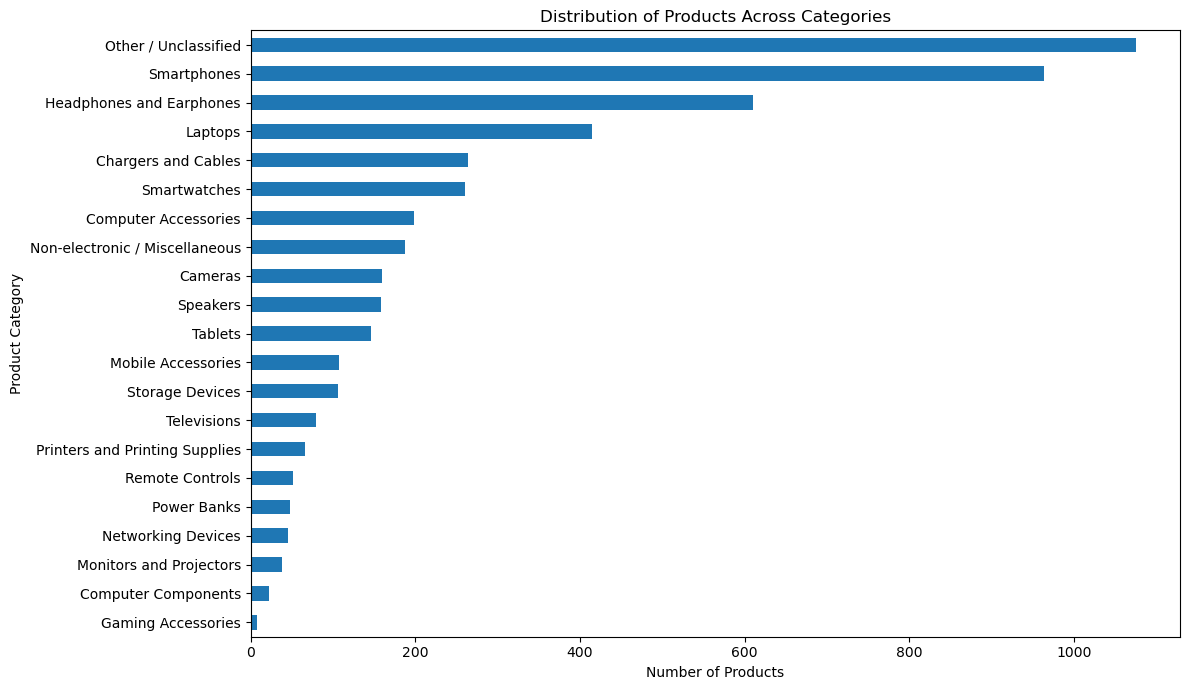


CATEGORY: Smartphones


,name
4095,amazon brand - solimo basic case for apple iphone 7 (silicone_transparent)
4652,spigen tough armor back cover case for samsung galaxy s23 ultra (poly carbonate + tpu | abyss green)
4900,thegiftkart ultra-hybrid crystal clear back cover case for samsung galaxy s22 ultra 5g | slim fit shockproof design | came...
4725,redclip ultimate cable protector | spiral triple colour 1.5 meter / 150 cm | plastic cord wire charger winder for iphone a...
3444,"redmi 10 (midnight black, 4gb ram, 64gb storage)"



CATEGORY: Headphones and Earphones


,name
382,boat bassheads 100 in-ear wired headphones with mic (white)
1111,"costar mateband bluetooth wireless neckband earphones - adjust eq for bombastic bass, 24 hours playtime, magnetic instant ..."
264,"jbl c200si, premium in ear wired earphones with mic, signature sound, one button multi-function remote, angled earbuds for..."
4904,storite 3.5mm jack 1 male to 2 female stereo headphone earphone jack y splitter audio auxiliary adapter cable (black)
1441,"zebronics sound bomb 7 bluetooth tws in ear earbuds with 40h playtime, enc mic, rapid charge, upto 50ms gaming mode, flash..."



CATEGORY: Smartwatches


,name
283,"noise colorfit pro 4 advanced bluetooth calling smart watch with 1.72"" truview display, fully-functional digital crown, 31..."
3166,"humble silicone 19mm replacement band strap with metal buckle compatible with noise colorfit pro 2 , storm smart watch & w..."
4069,"envous smart watch charger magnetic, charging cable for boat xtend, noise colorfit pulse, colorfit ultra/ultra 2, color fi..."
3311,"(renewed) fire-boltt phoenix pro 1.39"" bluetooth calling smartwatch, ai voice assistant, metal body with 120+ sports mode..."
3883,new edition i7 pro max all in one series 7 smart watch with fitness tracker heart monitor men women smart watch black


... (32 outputs left out)


CATEGORY: Monitors and Projectors


,name
4343,70mai hardwire cable kit for 24 hour parking monitoring with 6 pcs fuse tap adapters for safe installation (2 pcs each of ...
4893,"viewsonic va2215-h full hd 1080p 22 inch led backlit display gaming monitor, amd freesync™ 75hz, superclear®, 3 side borde..."
1278,"boat wave style with 1.69"" square hd display, hr & spo2 monitoring, 7 days battery life, multiple watch faces, crest app h..."
2243,omron karada scan body composition monitor hbf-375
4011,"lenovo l-series 60.45 cm (24 inch) fhd ips ultraslim monitor | 16.7 million colors, 75hz, amd freesync, hdmi, tilt, vesa m..."



CATEGORY: Mobile Accessories


,name
4105,opentech® tempered glass screen protector compatible for oneplus 7t edge to edge coverage with easy installation kit
1352,"cable management box with mobile stand - cord organizer hides extention board, power strips, surge protector, cords, wire,..."
899,"wecool s3 selfie stick with detachable wireless remote , 3 in 1 function sturdy tripod stand and mobile stand bluetooth se..."
4720,vmt stock oneplus11r 5g back cover pc back case with bumper drop protection case cover for oneplus 11r 5g
4010,thegiftkart rugged carbon fibre armor back cover case for oneplus 6t / oneplus 7 (tpu | blue)


In [5]:
import re

def classify_product(title):
    title = str(title).lower()

    # Non-electronic products first
    non_electronic = [
        "scissor", "pen ", "roller pen", "fountain pen",
        "whiteboard", "poster colour", "paint brush",
        "hook and loop tape", "stationery"
    ]

    if any(word in title for word in non_electronic):
        return "Non-electronic / Miscellaneous"

    categories = {
        "Smartphones": [
            "smartphone", "mobile phone", "iphone",
            "redmi", "oneplus nord", "samsung galaxy",
            "iqoo", "vivo", "oppo", "pixel"
        ],

        "Laptops": [
            "laptop", "notebook computer", "macbook"
        ],

        "Tablets": [
            "tablet", "ipad", "lenovo tab"
        ],

        "Headphones and Earphones": [
            "headphone", "earphone", "earbuds",
            "airpods", "neckband", "headset"
        ],

        "Smartwatches": [
            "smartwatch", "smart watch", "fitness band",
            "fitness tracker"
        ],

        "Speakers": [
            "speaker", "soundbar", "home theatre"
        ],

        "Cameras": [
            "camera", "webcam", "dslr"
        ],

        "Televisions": [
            "television", "smart tv", "led tv", "bravia"
        ],

        "Monitors and Projectors": [
            "monitor", "projector"
        ],

        "Storage Devices": [
            "pendrive", "pen drive", "usb drive",
            "memory card", "micro sd", "hard disk",
            "ssd", "flash drive"
        ],

        "Computer Components": [
            "ram memory", "ddr4", "ddr5",
            "graphics card", "motherboard",
            "processor", "computer memory"
        ],

        "Printers and Printing Supplies": [
            "printer", "ink cartridge", "printhead",
            "toner cartridge"
        ],

        "Networking Devices": [
            "router", "modem", "hotspot",
            "wifi adapter", "network switch"
        ],

        "Power Banks": [
            "power bank", "charging station"
        ],

        "Chargers and Cables": [
            "charger", "charging cable", "usb cable",
            "type c cable", "adapter"
        ],

        "Mobile Accessories": [
            "phone case", "back cover", "screen protector",
            "tempered glass", "mobile holder",
            "phone holder", "mobile stand"
        ],

        "Remote Controls": [
            "remote control", "tv remote", "remote"
        ],

        "Computer Accessories": [
            "mouse", "keyboard", "laptop bag",
            "mouse pad", "laptop stand", "monitor stand"
        ],

        "Gaming Accessories": [
            "gaming controller", "gamepad",
            "gaming mouse", "gaming keyboard"
        ]
    }

    for category, keywords in categories.items():
        if any(word in title for word in keywords):
            return category

    return "Other / Unclassified"


df["product_category"] = df["name"].apply(classify_product)

category_counts = (
    df["product_category"]
    .value_counts()
    .rename_axis("Product Category")
    .reset_index(name="Product Count")
)

display(category_counts)

print("Total products:", len(df))
print("Unclassified:",
      (df["product_category"] == "Other / Unclassified").sum())
print("Non-electronic:",
      (df["product_category"] ==
       "Non-electronic / Miscellaneous").sum())

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

category_counts_sorted = (
    df["product_category"].value_counts().sort_values()
)

category_counts_sorted.plot(kind="barh")

plt.title("Distribution of Products Across Categories")
plt.xlabel("Number of Products")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

for category in df["product_category"].unique():

    print("\nCATEGORY:", category)

    display(
        df[df["product_category"] == category][["name"]]
        .sample(
            min(5, len(df[df["product_category"] == category])),
            random_state=42
        )
    )

In [6]:
def classify_product(title):
    title = str(title).lower()

    categories = [
        ("Non-electronic / Miscellaneous", [
            "scissor", "fountain pen", "roller pen",
            "whiteboard", "poster colour", "notebook",
            "flash cards", "e-gift card", "stationery"
        ]),

        ("Mobile Accessories", [
            "phone case", "back cover", "screen protector",
            "tempered glass", "mobile holder", "phone holder",
            "cable protector", "mobile stand"
        ]),

        ("Computer Accessories", [
            "laptop bag", "laptop stand", "laptop riser",
            "laptop sleeve", "mouse", "keyboard",
            "mouse pad", "monitor stand"
        ]),

        ("Camera Accessories", [
            "camera holder", "tripod", "monopod",
            "camera mount", "camera lens"
        ]),

        ("Cables and Adapters", [
            "usb cable", "charging cable", "audio jack",
            "jack splitter", "connector", "usb adapter"
        ]),

        ("Electrical Accessories", [
            "extension cord", "extension board",
            "surge guard", "power strip", "spike guard"
        ]),

        ("Batteries", [
            "battery", "batteries"
        ]),

        ("Power Banks", [
            "power bank"
        ]),

        ("Smartphones", [
            "smartphone", "mobile phone", "iphone",
            "redmi", "oneplus nord", "samsung galaxy",
            "iqoo", "vivo", "oppo", "pixel"
        ]),

        ("Laptops", [
            "laptop", "macbook", "notebook computer"
        ]),

        ("Tablets", [
            "tablet", "ipad", "lenovo tab"
        ]),

        ("Headphones and Earphones", [
            "headphone", "earphone", "earbuds",
            "airpods", "neckband", "headset"
        ]),

        ("Smartwatches", [
            "smartwatch", "smart watch", "fitness band"
        ]),

        ("Speakers", [
            "speaker", "soundbar", "home theatre"
        ]),

        ("Cameras", [
            "digital camera", "dslr", "mirrorless camera",
            "webcam"
        ]),

        ("Televisions", [
            "television", "smart tv", "led tv", "bravia"
        ]),

        ("Monitors and Projectors", [
            "monitor", "projector"
        ]),

        ("Storage Devices", [
            "pendrive", "pen drive", "usb drive",
            "memory card", "hard disk", "ssd",
            "flash drive"
        ]),

        ("Computer Components", [
            "ram memory", "ddr4", "ddr5",
            "graphics card", "motherboard", "processor"
        ]),

        ("Printers and Printing Supplies", [
            "printer", "ink cartridge", "printhead",
            "toner cartridge"
        ]),

        ("Networking Devices", [
            "router", "modem", "hotspot",
            "wifi adapter", "network switch"
        ]),

        ("Remote Controls", [
            "remote control", "tv remote"
        ])
    ]

    for category, keywords in categories:
        if any(keyword in title for keyword in keywords):
            return category

    return "Other / Unclassified"


df["product_category"] = df["name"].apply(classify_product)

display(
    df["product_category"]
    .value_counts()
    .to_frame("Product Count")
)

for category in df["product_category"].unique():

    print("\nCATEGORY:", category)

    sample = df[
        df["product_category"] == category
    ][["name"]].sample(
        min(5, (df["product_category"] == category).sum()),
        random_state=42
    )

    display(sample)

,Product Count
product_category,
Other / Unclassified,1247
Headphones and Earphones,551
Mobile Accessories,536
Smartphones,506
Computer Accessories,329
Batteries,268
Laptops,249
Smartwatches,215
Cables and Adapters,205



CATEGORY: Smartphones


,name
1682,"samsung galaxy s23 ultra 5g (green, 12gb, 256gb storage)"
2786,"samsung galaxy tab a8 10.5 inches display with calling, ram 4 gb, rom 64 gb expandable, wi-fi+lte tablets, gray, (sm-x205n..."
4898,"ambrane 36w fast car charger with dual output, qualcomm quick charge 3.0 compatible with all cars for iphone, all smartpho..."
643,"samsung galaxy m53 5g (mystique green, 6gb, 128gb storage) | 108mp | samoled+ 120hz | 12gb ram with ram plus | travel adap..."
4440,jgd products for samsung galaxy s23 ultra 5g premium transparent hybrid soft slim dust proof back case cover



CATEGORY: Headphones and Earphones


,name
4992,sh-12 wireless bluetooth over the ear headphone with mic (black)
386,"boult audio z25 true wireless in ear earbuds with 32h playtime, 45ms low latency, type-c fast charging (10=150mins), made ..."
685,"noise buds vs104 pro truly wireless earbuds with 40h of playtime, quad mic with enc, instacharge(10 min=150 min), 14.2mm d..."
384,"boult audio fxcharge wireless in ear bluetooth neckband with enc mic, 32h playtime, type-c fast charging (5mins=7.5hrs pla..."
1706,oneassist 2 years extended warranty plan for headphones 500 to 1000 - email delivery within 2 hours



CATEGORY: Batteries


... (37 outputs left out)


CATEGORY: Laptops


,name
3184,adisa laptop backpack 31 ltrs
431,memeho® smart standard multi-purpose laptop table with dock stand/study table/bed table/foldable and portable/ergonomic & ...
2385,adisa light weight laptop backpack 32 ltrs
1647,"tp-link uh400 usb 3.0 4-port portable data hub for mac, imac, macbook pro air, ultrabooks, tablet, laptop and any pc, wind..."
2642,lenovo gx20p92532 65w ac adapter/charger with power cord for select models of lenovo (type-c pin) laptops black



CATEGORY: Remote Controls


,name
2301,lohaya air conditioner remote compatible daikin split ac remote control [ compatible for daikin ac remote ] [ ac-132a ]
3111,"smashtronics® - case for firetv remote, fire stick remote cover case, silicone cover for tv firestick 4k/tv 2nd gen(3rd ge..."
263,sounce shutter remote control with bluetooth wireless technology - create amazing photos and videos hands-free - works wit...
4737,"r for rabbit lullabies automatic swing baby cradle with remote control & mosquito net, soothing musical swing cradles, ele..."
2510,electvision remote compatible with amazon fire stick remote only [3rd generation ][ fire tv remote ] [ fire stick remote ]...


In [7]:
battery_products = df[
    df["product_category"] == "Batteries"
]

display(
    battery_products[
        ["name", "product_category"]
    ].head(40)
)

unclassified = df[
    df["product_category"] == "Other / Unclassified"
]

display(
    unclassified[["name"]].sample(
        40,
        random_state=42
    )
)

,name,product_category
3,"samsung galaxy m33 5g (mystique green, 6gb, 128gb storage) | 6000mah battery | upto 12gb ram with ram plus | travel adapte...",Batteries
9,"samsung galaxy m33 5g (emerald brown, 6gb, 128gb storage) | 6000mah battery | upto 12gb ram with ram plus | travel adapter...",Batteries
11,"redmi a1 (light blue, 2gb ram, 32gb storage) | segment best ai dual cam | 5000mah battery | leather texture design | andro...",Batteries
20,"boat airdopes 121v2 in-ear true wireless earbuds with upto 14 hours playback, 8mm drivers, battery indicators, lightweight...",Batteries
21,"redmi a1 (black, 2gb ram, 32gb storage) | segment best ai dual cam | 5000mah battery | leather texture design | android 12",Batteries
22,"redmi 10a (charcoal black, 4gb ram, 64gb storage) | 2 ghz octa core helio g25 | 5000 mah battery | finger print sensor | u...",Batteries
35,"redmi a1 (light green, 2gb ram 32gb rom) | segment best ai dual cam | 5000mah battery | leather texture design | android 12",Batteries
41,"tagg verve sense smartwatch with 1.70'' large display, real spo2, and real-time heart rate tracking, 7 days battery backu...",Batteries
43,"samsung galaxy m04 light green, 4gb ram, 64gb storage | upto 8gb ram with ram plus | mediatek helio p35 | 5000 mah battery",Batteries
49,"redmi 10a (slate grey, 4gb ram, 64gb storage) | 2 ghz octa core helio g25 | 5000 mah battery | finger print sensor | upto ...",Batteries


,name
2811,"boat xtend pro with advanced dedicated bluetooth calling chip, dial pad, 1.78” amoled display, asap™(fast) charge, 700+ ac..."
4600,"gm 3245 meridian 2 pin flex box cord length 4.8 to 5 mtr. with handle, indicator & international socket (assorted color)"
3639,"omron mc 343 flexible tip digital thermometer with quick measurement of oral, underarm temperature in celsius & fahrenhei..."
1222,portronics konnect l por-1403 fast charging 3a type-c cable 1.2 meter with charge & sync function for all type-c devices (...
1532,"house of quirk electronics accessories organizer bag, universal carry travel gadget bag for cables, plug and more, perfect..."
2069,"vega blooming air foldable 1000 watts hair dryer with heat & cool setting and detachable nozzle (vhdh-05), color may vary,..."
1243,"prolet 20mm silicone strap compatible with amazfit gts 2 mini, amazfit bip/bip u/pro/lite, bip s, amazfit gts/ 2/2e, amazf..."
490,"casio fx-82ms 2nd gen non-programmable scientific calculator, 240 functions and 2-line display, black"
270,oneplus 80 cm (32 inches) y series hd ready led smart android tv 32y1 (black)
3849,"mi xiao usb type c hypercharge cable 6a 100cm sturdy and durable black supports 120w hypercharging, compatible with smartp..."


In [9]:
import re

def classify_product(title):
    title = str(title).lower()

    # 1. Accessories first: identify what the product actually is
    accessory_rules = {
        "Mobile Accessories": [
            "back cover", "phone case", "mobile case",
            "screen protector", "tempered glass",
            "phone holder", "mobile holder"
        ],

        "Smartwatch Accessories": [
            "watch strap", "watch band", "replacement band",
            "watch charger", "smartwatch charger"
        ],

        "Computer Accessories": [
            "laptop stand", "laptop bag", "laptop sleeve",
            "mouse pad", "wireless mouse", "keyboard",
            "computer bag"
        ],

        "Chargers and Cables": [
            "charger", "charging cable", "usb cable",
            "type-c cable", "adapter", "power cord"
        ],

        "Camera Accessories": [
            "camera tripod", "selfie stick",
            "camera holder", "camera mount"
        ]
    }

    for category, keywords in accessory_rules.items():
        if any(word in title for word in keywords):
            return category

    # 2. Main electronic products
    product_rules = {
        "Smartphones": [
            "smartphone", "mobile phone", "iphone",
            "samsung galaxy", "redmi", "realme narzo",
            "oneplus", "oppo", "vivo"
        ],

        "Tablets": [
            "tablet", "ipad", "galaxy tab", "lenovo tab"
        ],

        "Laptops": [
            "laptop", "macbook", "notebook computer"
        ],

        "Headphones and Earphones": [
            "headphone", "earphone", "earbuds",
            "airpods", "neckband", "headset"
        ],

        "Smartwatches": [
            "smartwatch", "smart watch"
        ],

        "Speakers": [
            "speaker", "soundbar"
        ],

        "Cameras": [
            "digital camera", "dslr", "mirrorless camera",
            "action camera", "webcam"
        ],

        "Televisions": [
            "smart tv", "led tv", "android tv",
            "oled tv", "television"
        ],

        "Storage Devices": [
            "hard disk", "external ssd", "internal ssd",
            "pen drive", "pendrive", "memory card"
        ],

        "Batteries": [
            "aaa battery",
            "aa battery",
            "coin battery",
            "lithium coin battery",
            "alkaline battery",
            "cr2032",
            "cr2025",
            "cr2016",
            "cr2450",
            "cr1220",
            "eneloop rechargeable battery"
        ],

        "Power Banks": [
            "power bank"
        ],

        "Networking Devices": [
            "router", "wifi extender", "network switch"
        ],

        "Monitors and Projectors": [
            "monitor", "projector"
        ],

        "Printers and Printing Supplies": [
            "printer", "ink cartridge", "toner cartridge"
        ],

        "Remote Controls": [
            "remote control", "tv remote"
        ]
    }

    for category, keywords in product_rules.items():
        if any(word in title for word in keywords):
            return category

    # 3. Anything not identified
    return "Other / Unclassified"


df["product_category"] = df["name"].apply(classify_product)

display(
    df["product_category"]
    .value_counts()
    .to_frame("Product Count")
)

battery_products = df[
    df["product_category"] == "Batteries"
]

display(
    battery_products[["name"]].head(30)
)
smartphones = df[
    df["product_category"] == "Smartphones"
]

display(smartphones[["name"]].head(20))
unclassified = df[
    df["product_category"] == "Other / Unclassified"
]

print("Unclassified:", len(unclassified))

display(
    unclassified[["name"]].sample(
        min(30, len(unclassified)),
        random_state=42
    )
)

,Product Count
product_category,
Other / Unclassified,1404
Headphones and Earphones,578
Chargers and Cables,525
Mobile Accessories,506
Smartphones,494
Computer Accessories,268
Smartwatches,231
Laptops,206
Tablets,159


,name
110,panasonic cr-2032/5be lithium coin battery - pack of 5
173,"duracell ultra alkaline aa battery, 4 pcs"
210,eveready 1015 carbon zinc aa battery - 10 pieces
245,duracell chhota power aa battery set of 10 pcs
506,"duracell specialty cr2025 lithium coin battery 3v, pack of 5 suitable for use in keyfobs, scales, wearables and medical de..."
600,"energizer cr2032, 3 volt zero mercury lithium battery"
665,panasonic lr44 alkaline coin battery - pack of 10
676,"duracell ultra alkaline aaa battery, 4 pcs"
1074,"energizer e96bp aaaa alkaline battery (2 pieces), silver"
1316,"duracell ultra alkaline aaa battery, 12 pcs"


,name
0,"redmi 10 power (power black, 8gb ram, 128gb storage)"
1,"oneplus nord ce 2 lite 5g (blue tide, 6gb ram, 128gb storage)"
2,"oneplus bullets z2 bluetooth wireless in ear earphones with mic, bombastic bass - 12.4 mm drivers, 10 mins charge - 20 hrs..."
3,"samsung galaxy m33 5g (mystique green, 6gb, 128gb storage) | 6000mah battery | upto 12gb ram with ram plus | travel adapte..."
4,"oneplus nord ce 2 lite 5g (black dusk, 6gb ram, 128gb storage)"
5,"redmi 10 power (sporty orange, 8gb ram, 128gb storage)"
11,"redmi a1 (light blue, 2gb ram, 32gb storage) | segment best ai dual cam | 5000mah battery | leather texture design | andro..."
12,"oneplus nord ce 2 lite 5g (blue tide, 8gb ram, 128gb storage)"
19,"oneplus bullets z2 bluetooth wireless in ear earphones with mic, bombastic bass - 12.4 mm drivers, 10 mins charge - 20 hrs..."
21,"redmi a1 (black, 2gb ram, 32gb storage) | segment best ai dual cam | 5000mah battery | leather texture design | android 12"


Unclassified: 1404


,name
3821,"asus tuf dash f15 (2022), 15.6"" (39.62 cms) fhd 144hz, intel core i5-12450h 12th gen, 4gb geforce rtx 3050 graphics, gamin..."
1904,cello technotip ball pen set (pack of 10 pens - black) | lightweight ball pens for pressure free & fine writing | exam pen...
2390,"agaro 3.5mm audio cable stereo aux 90 degree right angle aux cable 24k gold plated male to male hi-fi sound for car, home ..."
2403,"amazon brand - solimo ring binder, a4 size, white, pack of 2"
3408,"fedus cat6 ethernet cable, 50 meter high speed 550mhz / 10 gigabit speed utp lan cable, network cable internet cable rj45 ..."
1395,"inefable® (10 pcs with black pouch) pubg anti-slip thumb sleeve, slip-proof sweat-proof professional touch screen thumbs f..."
4145,mi micro usb 100cm braided cable red micro usb/type b|tangle free |sturdy built with kevlar protection|480mbps speed|suppo...
520,"amazonbasics expanding file folder, letter size (fits a4 paper) - black - with 13 pockets"
405,"sandisk ultra dual drive luxe usb type c flash drive (silver, 128 gb, 5y - sdddc4-128g-i35)"
2688,"digitek® (drl-15c rgb) led rgb ring light with stand for youtube, photo-shoot, video shoot, live stream, makeup & more, co..."


In [20]:
import re
import numpy as np
import pandas as pd


def extract_specs(title):
    title = str(title).lower()

    specs = {
        "ram_gb": np.nan,
        "storage_gb": np.nan,
        "battery_mah": np.nan,
        "screen_inches": np.nan,
        "charging_w": np.nan,
        "refresh_rate_hz": np.nan
    }

    # ---------------------------------
    # 1. RAM
    # ---------------------------------
    ram_matches = re.finditer(r'(\d+)\s*gb\s*ram', title)

    for match in ram_matches:
        prefix = title[max(0, match.start()-15):match.start()]

        if "upto" not in prefix:
            specs["ram_gb"] = float(match.group(1))
            break

    # Fallback for titles such as 4GB, 64GB storage
    if pd.isna(specs["ram_gb"]):
        ram_fallback = re.search(
            r'(\d+)\s*gb\s*,\s*\d+\s*gb\s*(?:storage|rom)',
            title
        )
        if ram_fallback:
            specs["ram_gb"] = float(ram_fallback.group(1))

    # ---------------------------------
    # 2. STORAGE
    # ---------------------------------
    storage = re.search(
        r'(\d+)\s*gb\s*(?:storage|rom)',
        title
    )

    if storage:
        specs["storage_gb"] = float(storage.group(1))

    # ---------------------------------
    # 3. BATTERY
    # ---------------------------------
    battery = re.search(
        r'(\d{3,5})\s*mah',
        title
    )

    if battery:
        specs["battery_mah"] = float(battery.group(1))

    # ---------------------------------
    # 4. SCREEN SIZE
    # ---------------------------------
    screen_context = (
        "display", "screen", "monitor", "television",
        "smartphone", "tablet", "laptop", "notebook",
        "smart watch", "smartwatch", "tv"
    )

    screen_matches = re.finditer(
        r'(\d+(?:\.\d+)?)\s*(?:inch|inches|")',
        title
    )

    for match in screen_matches:
        prefix = title[max(0, match.start()-35):match.start()]
        context = title[max(0, match.start()-60):match.end()+40]

        value = float(match.group(1))

        if (
            1.0 <= value <= 100
            and any(word in context for word in screen_context)
            and "up to" not in prefix
            and "compartment" not in context
        ):
            specs["screen_inches"] = value
            break

    # ---------------------------------
    # 5. CHARGING POWER
    # ---------------------------------
    charging_matches = re.finditer(
        r'(\d+(?:\.\d+)?)\s*w(?:att)?\b',
        title
    )

    charging_context = (
        "charging", "charger", "charge", "power delivery",
        "pd charger", "quick charge", "fast charge"
    )

    for match in charging_matches:
        context = title[max(0, match.start()-35):match.end()+55]
        value = float(match.group(1))

        if (
            1 <= value <= 300
            and any(word in context for word in charging_context)
        ):
            specs["charging_w"] = value
            break

    # ---------------------------------
    # 6. REFRESH RATE
    # ---------------------------------
    refresh_matches = re.finditer(
        r'(\d+)\s*hz\b',
        title
    )

    refresh_context = (
        "display", "screen", "monitor", "refresh",
        "amoled", "oled", "gaming", "smartphone",
        "laptop", "tablet"
    )

    for match in refresh_matches:
        context = title[max(0, match.start()-45):match.end()+35]
        value = float(match.group(1))

        if (
            30 <= value <= 360
            and any(word in context for word in refresh_context)
        ):
            specs["refresh_rate_hz"] = value
            break

    return pd.Series(specs)

spec_features = df["name"].apply(extract_specs)

df = df.drop(columns=spec_features.columns, errors="ignore")

df = pd.concat([df, spec_features], axis=1)



display(df[
    ["name", "ram_gb", "storage_gb", "battery_mah",
     "screen_inches", "charging_w", "refresh_rate_hz"]
].head(20))

,name,ram_gb,storage_gb,battery_mah,screen_inches,charging_w,refresh_rate_hz
0,"redmi 10 power (power black, 8gb ram, 128gb storage)",8.0,128.0,NaN,NaN,NaN,NaN
1,"oneplus nord ce 2 lite 5g (blue tide, 6gb ram, 128gb storage)",6.0,128.0,NaN,NaN,NaN,NaN
2,"oneplus bullets z2 bluetooth wireless in ear earphones with mic, bombastic bass - 12.4 mm drivers, 10 mins charge - 20 hrs...",NaN,NaN,NaN,NaN,NaN,NaN
3,"samsung galaxy m33 5g (mystique green, 6gb, 128gb storage) | 6000mah battery | upto 12gb ram with ram plus | travel adapte...",6.0,128.0,6000.0,NaN,NaN,NaN
4,"oneplus nord ce 2 lite 5g (black dusk, 6gb ram, 128gb storage)",6.0,128.0,NaN,NaN,NaN,NaN
5,"redmi 10 power (sporty orange, 8gb ram, 128gb storage)",8.0,128.0,NaN,NaN,NaN,NaN
6,"boat airdopes 141 bluetooth truly wireless in ear earbuds with mic, 42h playtime, beast mode(low latency upto 80ms) for ga...",NaN,NaN,NaN,NaN,NaN,NaN
7,"apple 20w usb-c power adapter (for iphone, ipad & airpods)",NaN,NaN,NaN,NaN,NaN,NaN
8,"fire-boltt ninja call pro plus 1.83"" smart watch with bluetooth calling, ai voice assistance, 100 sports modes ip67 ratin...",NaN,NaN,NaN,1.83,NaN,NaN
9,"samsung galaxy m33 5g (emerald brown, 6gb, 128gb storage) | 6000mah battery | upto 12gb ram with ram plus | travel adapter...",6.0,128.0,6000.0,NaN,NaN,NaN


In [21]:
# Keep the latest version of duplicate columns
df = df.loc[:, ~df.columns.duplicated(keep="last")]

# Check column names
print("Duplicate columns:", df.columns[df.columns.duplicated()].tolist())

display(df[
    ["name", "ram_gb", "storage_gb", "battery_mah",
     "screen_inches", "charging_w", "refresh_rate_hz"]
].head(20))



Duplicate columns: []


,name,ram_gb,storage_gb,battery_mah,screen_inches,charging_w,refresh_rate_hz
0,"redmi 10 power (power black, 8gb ram, 128gb storage)",8.0,128.0,NaN,NaN,NaN,NaN
1,"oneplus nord ce 2 lite 5g (blue tide, 6gb ram, 128gb storage)",6.0,128.0,NaN,NaN,NaN,NaN
2,"oneplus bullets z2 bluetooth wireless in ear earphones with mic, bombastic bass - 12.4 mm drivers, 10 mins charge - 20 hrs...",NaN,NaN,NaN,NaN,NaN,NaN
3,"samsung galaxy m33 5g (mystique green, 6gb, 128gb storage) | 6000mah battery | upto 12gb ram with ram plus | travel adapte...",6.0,128.0,6000.0,NaN,NaN,NaN
4,"oneplus nord ce 2 lite 5g (black dusk, 6gb ram, 128gb storage)",6.0,128.0,NaN,NaN,NaN,NaN
5,"redmi 10 power (sporty orange, 8gb ram, 128gb storage)",8.0,128.0,NaN,NaN,NaN,NaN
6,"boat airdopes 141 bluetooth truly wireless in ear earbuds with mic, 42h playtime, beast mode(low latency upto 80ms) for ga...",NaN,NaN,NaN,NaN,NaN,NaN
7,"apple 20w usb-c power adapter (for iphone, ipad & airpods)",NaN,NaN,NaN,NaN,NaN,NaN
8,"fire-boltt ninja call pro plus 1.83"" smart watch with bluetooth calling, ai voice assistance, 100 sports modes ip67 ratin...",NaN,NaN,NaN,1.83,NaN,NaN
9,"samsung galaxy m33 5g (emerald brown, 6gb, 128gb storage) | 6000mah battery | upto 12gb ram with ram plus | travel adapter...",6.0,128.0,6000.0,NaN,NaN,NaN


In [22]:
feature_columns = [
    "ram_gb",
    "storage_gb",
    "battery_mah",
    "screen_inches",
    "charging_w",
    "refresh_rate_hz"
]

coverage = pd.DataFrame({
    "Available": df[feature_columns].notna().sum(),
    "Missing": df[feature_columns].isna().sum(),
    "Coverage (%)": (
        df[feature_columns].notna().mean() * 100
    ).round(2)
})

display(coverage.sort_values("Coverage (%)", ascending=False))

,Available,Missing,Coverage (%)
screen_inches,358,4652,7.15
ram_gb,263,4747,5.25
storage_gb,226,4784,4.51
charging_w,220,4790,4.39
battery_mah,152,4858,3.03
refresh_rate_hz,49,4961,0.98


In [23]:
for col in feature_columns:
    print(f"\n{'='*45}")
    print(f"FEATURE: {col}")
    print("Unique values:", df[col].nunique())
    print("Minimum:", df[col].min())
    print("Maximum:", df[col].max())
    print("Median:", df[col].median())

    display(
        df[["name", col]]
        .dropna()
        .sample(
            min(10, df[col].notna().sum()),
            random_state=42
        )
    )


FEATURE: ram_gb
Unique values: 7
Minimum: 2.0
Maximum: 16.0
Median: 6.0


,name,ram_gb
1148,"realme c35 (glowing green, 4gb ram, 64gb storage)",4.0
1248,"oneplus 11 5g (eternal green, 8gb ram, 128gb storage)",8.0
4953,"hp 14s, 5th gen amd ryzen 3- 8gb ram/512gb ssd 14 inches(35cm) laptop, fhd ips micro-edge display/ backlit keyboard/alexa/...",8.0
3754,"samsung galaxy a14 5g (light green, 6gb, 128gb storage) | triple rear camera (50 mp main) | upto 12 gb ram with ram plus |...",6.0
421,realme narzo 50i prime (mint green 3gb ram+32gb storage) octa-core processor | 5000 mah battery,3.0
4587,"tecno pop 5 lte (ice blue, 2gb ram,32gb storage) | front flash | 8mp dual camera",2.0
2316,realme narzo 50 pro 5g (hyper black 8gb ram+128gb storage) dimensity 920 5g processor |90hz super amoled display,8.0
3348,"redmi k50i 5g (stealth black, 8gb ram, 256gb storage) | flagship mediatek dimensity 8100 processor | 144hz liquid ffs disp...",8.0
21,"redmi a1 (black, 2gb ram, 32gb storage) | segment best ai dual cam | 5000mah battery | leather texture design | android 12",2.0
886,"nokia c12 android 12 (go edition) smartphone, all-day battery, 4gb ram (2gb ram + 2gb virtual ram) + 64gb capacity | light...",4.0



FEATURE: storage_gb
Unique values: 4
Minimum: 32.0
Maximum: 256.0
Median: 128.0


,name,storage_gb
21,"redmi a1 (black, 2gb ram, 32gb storage) | segment best ai dual cam | 5000mah battery | leather texture design | android 12",32.0
3043,"tecno pop 5 lte (deepsea luster, 2gb ram,32gb storage) | front flash | 8mp dual camera",32.0
1447,"tecno pop 6 pro (peaceful blue, 2gb ram,32gb storage) | front flash | 8mp dual camera",32.0
4295,"redmi 11 prime (flashy black, 6gb ram, 128gb storage) | prime design | high performance helio g99 | 50 mp ai triple cam | ...",128.0
2154,"tecno spark 9 (infinity black, 4gb ram,64gb storage) | 7gb expandable ram | helio g37 gaming processor",64.0
4713,"xifo lyf earth 1 (3gb ram, 32gb storage) 4g smartphone in white colour",32.0
2998,redmi 10 prime (astral white 4gb ram 64gb rom |helio g88 with extendable ram upto 2gb |fhd+ 90hz adaptive sync display),64.0
784,"iqoo z6 5g by vivo (dynamo black, 4gb ram, 128gb storage) | snapdragon 695-6nm processor | 120hz fhd+ display | travel ada...",128.0
2780,"samsung galaxy m13 5g (stardust brown, 4gb, 64gb storage) | 5000mah battery | upto 8gb ram with ram plus",64.0
2763,"redmi 10 (pacific blue, 4gb ram, 64gb storage)",64.0



FEATURE: battery_mah
Unique values: 31
Minimum: 500.0
Maximum: 50000.0
Median: 6000.0


,name,battery_mah
1172,"airtel digitaltv amf-311ww 150mbps single_band data card (black), 4g hotspot support with 2300 mah battery",2300.0
4815,urbn 20000 mah 20w super fast charging metal power bank | type c pd (input& output) | qc 3.0 dual usb output | two-way fas...,20000.0
2245,"amazonbasics bluetooth speaker 5.0 soundbar with 16w rms, 2000mah battery, upto 19 hrs playtime aux/usb port (black)",2000.0
1638,urbn 20000 mah li-polymer ultra compact power bank | 12w fast charge | dual usb output | type c & micro input (blue),20000.0
4130,"portronics breeze plus por-545 20w bluetooth 5.0 portable stereo speaker with tws, aux in, water resistant, 2000mah batter...",2000.0
4282,"redmi 10000mah lithium polymer power bank with 10 watt fast charging, (white)",10000.0
275,duracell plus aaa rechargeable batteries (750 mah) pack of 4,750.0
82,"redmi 10a (sea blue, 4gb ram, 64gb storage) | 2 ghz octa core helio g25 | 5000 mah battery | finger print sensor | upto 5g...",5000.0
163,"samsung galaxy m33 5g (mystique green, 8gb, 128gb storage) | 6000mah battery | upto 16gb ram with ram plus | travel adapte...",6000.0
112,"mi 10000mah lithium ion, lithium polymer power bank pocket pro with 22.5 watt fast charging, dual input ports(micro-usb an...",10000.0


... (2 outputs left out)


FEATURE: charging_w
Unique values: 30
Minimum: 5.0
Maximum: 200.0
Median: 22.5


,name,charging_w
2579,spigen pe2008 fast gan wall charger 30w 1-port designed for all c type mobile phones and devices - black,30.0
3068,"myvn 65w super vooc charge, data sync fast charging type-c cable compatible for realme xt, realme xt 730g, realme x2, real...",65.0
1764,wayona usb type c 65w 6ft/2m long fast charging cable compatible for samsung s22 s20 fe s21 ultra a33 a53 a01 a73 a70 a51 ...,65.0
3878,original 25w usb-c super fast charger true 25w pd charging adapter compatible for samsung (white) (white),25.0
336,"iqoo z6 pro 5g by vivo (phantom dusk, 6gb ram, 128gb storage) | snapdragon 778g 5g | 66w flashcharge | 1300 nits peak brig...",66.0
2177,"redmi lithiumpolymer 10000 mah fast charging slim power bank (black, 10w fast charging, dual ports)",10.0
3589,urbn 10000 mah 20w super fast charging metal power bank | type c pd (input& output) qc 3.0 dual usb output | two-way fast ...,20.0
4709,eller santé® 15w wireless charger montclad series fast charging pad| pd & qi-certified with type c cable fireproof abs for...,15.0
1448,"wayona type c to lightning mfi certified 20w fast charging nylon braided usb c cable for iphone 14,14 pro,14 pro max,14 pl...",20.0
2898,amazon basics car charger with 36w fast charging | dual port -type c and usb output | micro usb cable included (grey),36.0



FEATURE: refresh_rate_hz
Unique values: 6
Minimum: 60.0
Maximum: 165.0
Median: 120.0


,name,refresh_rate_hz
784,"iqoo z6 5g by vivo (dynamo black, 4gb ram, 128gb storage) | snapdragon 695-6nm processor | 120hz fhd+ display | travel ada...",120.0
4485,"lenovo l-series 68.58 cm (27 inch) fhd ips ultraslim monitor |16.7 mn colors, 75hz, 4ms, amd freesync, hdmi, tuv eye comfo...",75.0
4893,"viewsonic va2215-h full hd 1080p 22 inch led backlit display gaming monitor, amd freesync™ 75hz, superclear®, 3 side borde...",75.0
4395,"redmi k50i 5g (phantom blue, 8gb ram, 256gb storage)| flagship mediatek dimensity 8100 processor | 144hz liquid ffs display",144.0
959,"samsung 24-inch (60.46cm) 1920 x 1080 pixels fhd monitor, ips, 75 hz, bezel less design, amd freesync, flicker free, hdmi,...",75.0
1821,"xiaomi pad 5| qualcomm snapdragon 860| 120hz refresh rate| 6gb, 128gb| 2.5k+ display (10.95-inch/27.81cm)|1 billion colour...",120.0
1812,"realme narzo 50 (speed blue, 4gb ram+64gb storage) 120hz full hd+ display | 50mp ai triple camera | helio g96 powerful gam...",120.0
1661,"samsung galaxy m53 5g (emerald brown, 6gb, 128gb storage) | 108mp | samoled+ 120hz | 12gb ram with ram plus | travel adapt...",120.0
2212,"redmi note 11 pro (stealth black, 8gb ram, 128gb storage)| 67w turbo charge | 120hz super amoled display | charger include...",120.0
1103,"oneplus nord watch with 1.78” amoled display, 60 hz refresh rate, 105 fitness modes, 10 days battery, spo2, heart rate, st...",60.0


In [18]:
%whos

Variable                 Type         Data/Info
-----------------------------------------------
Counter                  type         <class 'collections.Counter'>
battery_products         DataFrame    Shape: (24, 18)
category                 str          Remote Controls
category_counts          DataFrame    Shape: (21, 2)
category_counts_sorted   Series       Shape: (21,)
classify_product         function     <function classify_product at 0x13f126ac0>
col                      str          refresh_rate_hz
coverage                 DataFrame    Shape: (6, 3)
dataframe_columns        function     <function dataframe_columns at 0x703797b6a0>
dataframe_hash           function     <function dataframe_hash at 0x7037979b20>
df                       DataFrame    Shape: (5010, 24)
dtypes_str               function     <function dtypes_str at 0x70379780e0>
extract_specs            function     <function extract_specs at 0x70379799e0>
feature_columns          list         n=6
get_dataframes       

In [19]:
import inspect

print(inspect.getsource(extract_specs))

def extract_specs(title):
    title = str(title).lower()

    specs = {
        "ram_gb": np.nan,
        "storage_gb": np.nan,
        "battery_mah": np.nan,
        "screen_inches": np.nan,
        "charging_w": np.nan,
        "refresh_rate_hz": np.nan
    }

    # RAM: Prefer explicit RAM values, excluding "upto" values
    ram_matches = re.finditer(r'(\d+)\s*gb\s*ram', title)

    for match in ram_matches:
        prefix = title[max(0, match.start()-10):match.start()]
        if "upto" not in prefix:
            specs["ram_gb"] = float(match.group(1))
            break

    # Fallback: first GB value when followed by another GB storage value
    if pd.isna(specs["ram_gb"]):
        ram_fallback = re.search(
            r'(\d+)\s*gb\s*,\s*\d+\s*gb\s*(?:storage|rom)',
            title
        )
        if ram_fallback:
            specs["ram_gb"] = float(ram_fallback.group(1))

    # Storage
    storage = re.search(
        r'(\d+)\s*gb\s*(?:storage|rom)',
        title
    )
    i

PHASE 5: FEATURE ENGINEERING
Original dataset shape: (5010, 24)
Total products: 5010

PRODUCT CLASSIFICATION COMPLETED
Total products: 5010

PRODUCT CATEGORY DISTRIBUTION


,Product Category,Product Count
0,Other / Unclassified,1344
1,Headphones and Earphones,682
2,Mobile Accessories,517
3,Smartphones,438
4,Chargers and Cables,378
5,Computer Accessories,260
6,Smartwatches,242
7,Laptops,188
8,Tablets,170
9,Storage Devices,132



Unclassified products: 1344
Unclassified percentage: 26.83 %
Non-electronic products: 95


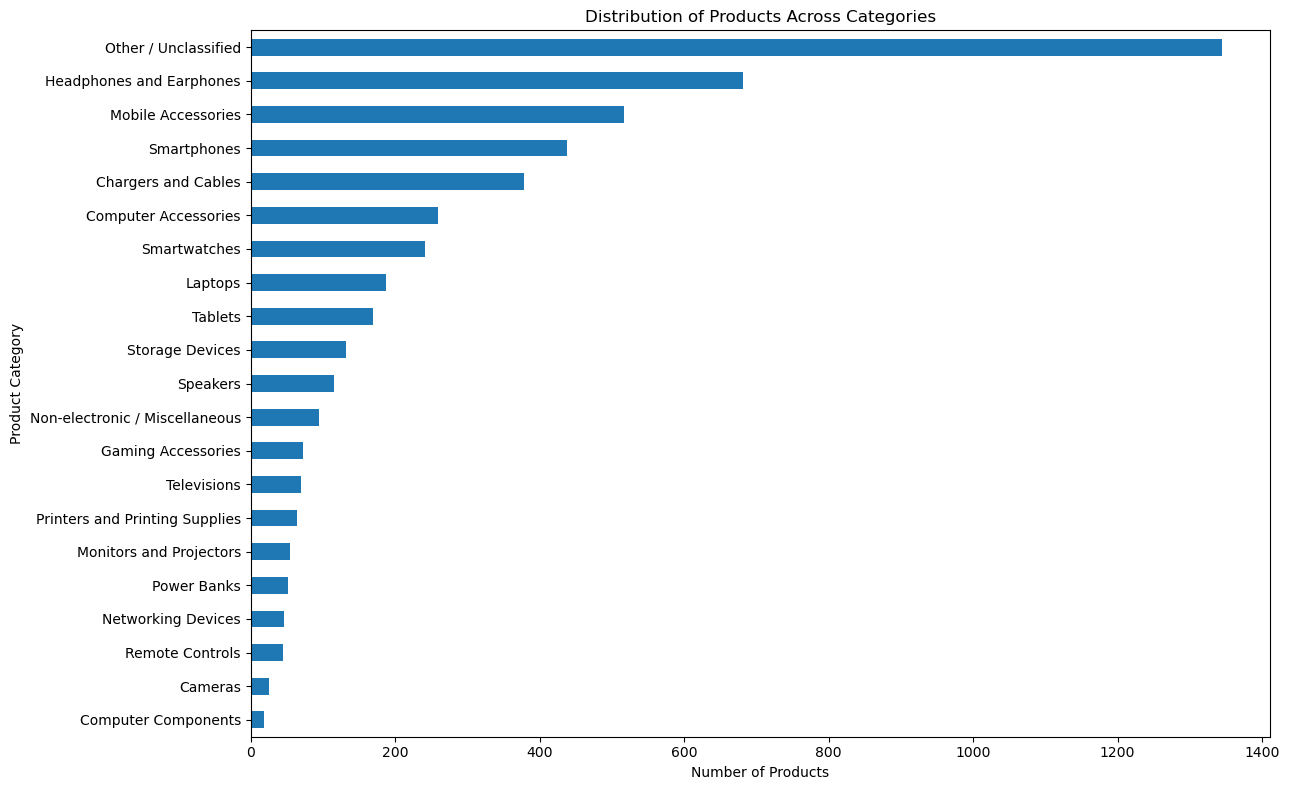


UNCLASSIFIED PRODUCT SAMPLES


,name
33,"sandisk ultra® microsdxc™ uhs-i card, 64gb, 140mb/s r, 10 y warranty, for smartphones"
38,samsung 25w usb travel adapter for cellular phones - white
42,"portronics toad 23 wireless optical mouse with 2.4ghz, usb nano dongle, optical orientation, click wheel, adjustable dpi(b..."
50,"jk copier paper - a4, 75 gsm, 1 ream, 500 sheets"
51,fire tv stick with alexa voice remote (includes tv and app controls) | hd streaming device
53,"scotch double sided heavy duty tape(1m holds 4.5kgs) for indoor hanging applications (photo frames, mirrors, key holders, ..."
63,"duracell alkaline aaa batteries, pack of 10"
73,"gm 3060 e-book 4 + 1 power strip 240 volts with master switch, indicator, safety shutter & 4 international sockets, red & ..."
75,"hp x1000 wired usb mouse with 3 handy buttons, fast-moving scroll wheel and optical sensor works on most surfaces, 3 years..."
81,"sandisk ultra® microsdxc™ uhs-i card, 128gb, 140mb/s r, 10 y warranty, for smartphones"



SPECIFICATION EXTRACTION COMPLETED


,name,product_category,ram_gb,storage_gb,battery_mah,screen_inches,charging_w,refresh_rate_hz
0,"redmi 10 power (power black, 8gb ram, 128gb storage)",Smartphones,8.0,128.0,NaN,NaN,NaN,NaN
1,"oneplus nord ce 2 lite 5g (blue tide, 6gb ram, 128gb storage)",Smartphones,6.0,128.0,NaN,NaN,NaN,NaN
2,"oneplus bullets z2 bluetooth wireless in ear earphones with mic, bombastic bass - 12.4 mm drivers, 10 mins charge - 20 hrs...",Headphones and Earphones,NaN,NaN,NaN,NaN,NaN,NaN
3,"samsung galaxy m33 5g (mystique green, 6gb, 128gb storage) | 6000mah battery | upto 12gb ram with ram plus | travel adapte...",Smartphones,6.0,128.0,6000.0,NaN,NaN,NaN
4,"oneplus nord ce 2 lite 5g (black dusk, 6gb ram, 128gb storage)",Smartphones,6.0,128.0,NaN,NaN,NaN,NaN
5,"redmi 10 power (sporty orange, 8gb ram, 128gb storage)",Smartphones,8.0,128.0,NaN,NaN,NaN,NaN
6,"boat airdopes 141 bluetooth truly wireless in ear earbuds with mic, 42h playtime, beast mode(low latency upto 80ms) for ga...",Headphones and Earphones,NaN,NaN,NaN,NaN,NaN,NaN
7,"apple 20w usb-c power adapter (for iphone, ipad & airpods)",Chargers and Cables,NaN,NaN,NaN,NaN,20.0,NaN
8,"fire-boltt ninja call pro plus 1.83"" smart watch with bluetooth calling, ai voice assistance, 100 sports modes ip67 ratin...",Smartwatches,NaN,NaN,NaN,NaN,NaN,NaN
9,"samsung galaxy m33 5g (emerald brown, 6gb, 128gb storage) | 6000mah battery | upto 12gb ram with ram plus | travel adapter...",Smartphones,6.0,128.0,6000.0,NaN,NaN,NaN



FEATURE COVERAGE REPORT


,Available,Missing,Coverage (%)
ram_gb,263,4747,5.25
charging_w,234,4776,4.67
storage_gb,229,4781,4.57
screen_inches,226,4784,4.51
battery_mah,121,4889,2.42
refresh_rate_hz,42,4968,0.84


... (2 outputs left out)


NUMERICAL VALIDATION REPORT


,Feature,Invalid Values,Valid Values
0,ram_gb,0,263
1,storage_gb,0,229
2,battery_mah,0,121
3,screen_inches,0,226
4,charging_w,0,234
5,refresh_rate_hz,0,42



FEATURE COVERAGE BY CATEGORY


,ram_gb,storage_gb,battery_mah,screen_inches,charging_w,refresh_rate_hz
product_category,,,,,,
Cameras,0.00,0.00,0.00,0.00,0.00,0.00
Chargers and Cables,3.97,3.44,0.00,0.00,41.80,0.00
Computer Accessories,0.77,0.00,0.00,0.00,0.00,0.00
Computer Components,0.00,0.00,0.00,0.00,0.00,0.00
Gaming Accessories,0.00,0.00,0.00,0.00,0.00,0.00
Headphones and Earphones,0.00,0.00,0.59,0.00,0.44,0.00
Laptops,5.85,0.00,0.00,2.13,0.00,0.00
Mobile Accessories,0.00,0.00,0.00,0.00,0.39,0.00
Monitors and Projectors,0.00,0.00,0.00,42.59,0.00,14.81


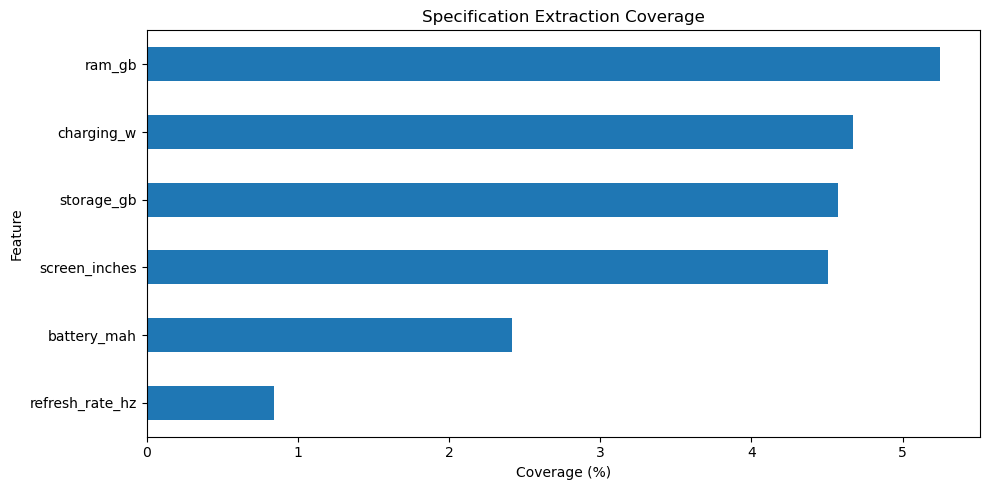

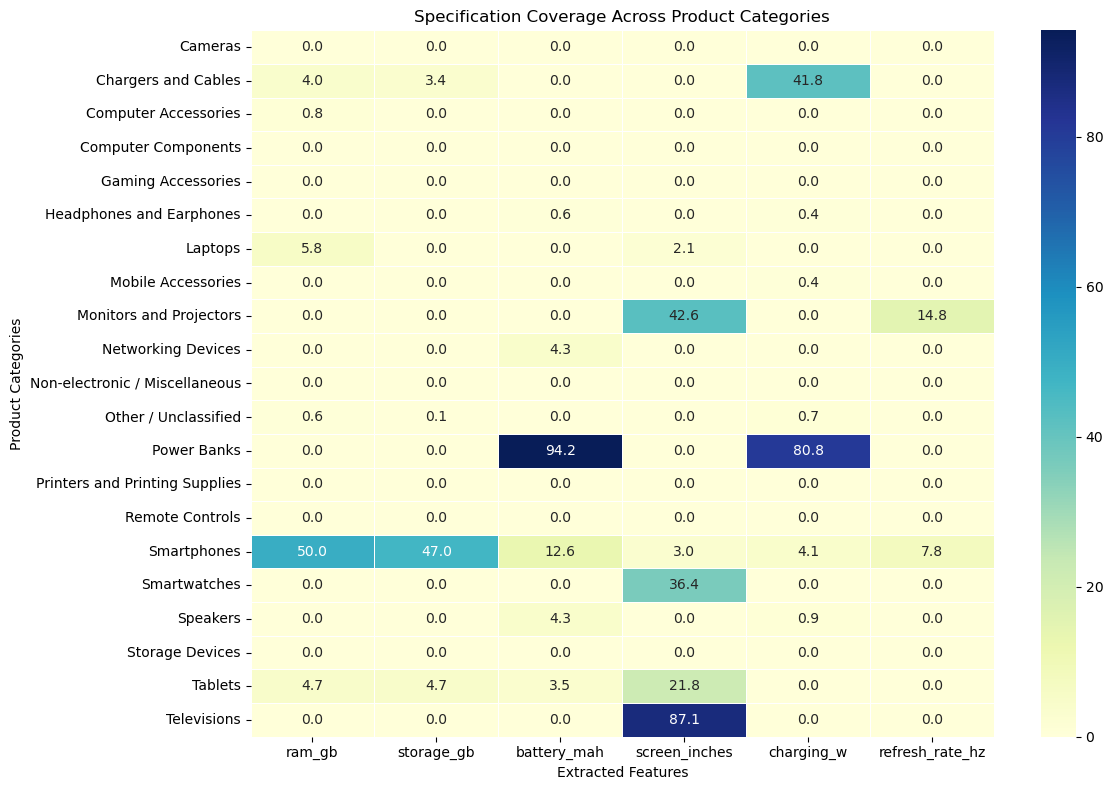


FEATURE: RAM_GB
Unique values: 7


,name,product_category,ram_gb
1148,"realme c35 (glowing green, 4gb ram, 64gb storage)",Smartphones,4.0
1248,"oneplus 11 5g (eternal green, 8gb ram, 128gb storage)",Smartphones,8.0
4953,"hp 14s, 5th gen amd ryzen 3- 8gb ram/512gb ssd 14 inches(35cm) laptop, fhd ips micro-edge display/ backlit keyboard/alexa/...",Computer Accessories,8.0
3754,"samsung galaxy a14 5g (light green, 6gb, 128gb storage) | triple rear camera (50 mp main) | upto 12 gb ram with ram plus |...",Smartphones,6.0
421,realme narzo 50i prime (mint green 3gb ram+32gb storage) octa-core processor | 5000 mah battery,Smartphones,3.0
4587,"tecno pop 5 lte (ice blue, 2gb ram,32gb storage) | front flash | 8mp dual camera",Smartphones,2.0
2316,realme narzo 50 pro 5g (hyper black 8gb ram+128gb storage) dimensity 920 5g processor |90hz super amoled display,Smartphones,8.0
3348,"redmi k50i 5g (stealth black, 8gb ram, 256gb storage) | flagship mediatek dimensity 8100 processor | 144hz liquid ffs disp...",Smartphones,8.0
21,"redmi a1 (black, 2gb ram, 32gb storage) | segment best ai dual cam | 5000mah battery | leather texture design | android 12",Smartphones,2.0
886,"nokia c12 android 12 (go edition) smartphone, all-day battery, 4gb ram (2gb ram + 2gb virtual ram) + 64gb capacity | light...",Smartphones,4.0



FEATURE: STORAGE_GB
Unique values: 4


,name,product_category,storage_gb
4572,"samsung galaxy a14 5g (light green, 8gb, 128gb storage) | triple rear camera (50 mp main) | upto 16 gb ram with ram plus |...",Smartphones,128.0
473,"redmi 11 prime 5g (thunder black, 4gb ram, 64gb storage) | prime design | mtk dimensity 700 | 50 mp dual cam | 5000mah | 7...",Smartphones,64.0
21,"redmi a1 (black, 2gb ram, 32gb storage) | segment best ai dual cam | 5000mah battery | leather texture design | android 12",Smartphones,32.0
3314,"realme narzo 50 (speed black, 6gb ram+128gb storage) helio g96 processor | 50mp ai triple camera | 120hz ultra smooth display",Smartphones,128.0
35,"redmi a1 (light green, 2gb ram 32gb rom) | segment best ai dual cam | 5000mah battery | leather texture design | android 12",Smartphones,32.0
3625,"jiofi jio phone next 32 gb rom, 2 gb ram, blue, smartphone",Smartphones,32.0
95,realme narzo 50 pro 5g (hyper blue 6gb ram+128gb storage) super amoled | advanced dimensity 920 5g gaming processor | 50% ...,Smartphones,128.0
3401,"vivo y22 (metaverse green, 6gb ram, 128gb storage) with no cost emi/additional exchange offers",Smartphones,128.0
2199,realme pad wifi+4g tablet | 3gb ram 32gb rom (expandable) | 26.4cm (10.4 inch) wuxga+ display | 7100 mah battery | dolby a...,Tablets,32.0
1529,"nokia c12 android 12 (go edition) smartphone, all-day battery, 4gb ram (2gb ram + 2gb virtual ram) + 64gb capacity | dark ...",Smartphones,64.0



FEATURE: BATTERY_MAH
Unique values: 18


,name,product_category,battery_mah
788,"samsung galaxy m13 (stardust brown, 6gb, 128gb storage) | 6000mah battery | upto 12gb ram with ram plus",Smartphones,6000.0
875,"redmi 10a sport (slate grey, 6gb ram, 128gb storage) | 2 ghz octa cor helio g25 | 5000 mah battery | finger print sensor |...",Smartphones,5000.0
22,"redmi 10a (charcoal black, 4gb ram, 64gb storage) | 2 ghz octa core helio g25 | 5000 mah battery | finger print sensor | u...",Smartphones,5000.0
1035,"ambrane 20000 mah lithium polymer stylo-20k power bank with 20 watt fast charging, 2 usb,type c port,green",Power Banks,20000.0
355,"samsung galaxy m04 light green, 4gb ram, 128gb storage | upto 8gb ram with ram plus | mediatek helio p35 | 5000 mah battery",Smartphones,5000.0
1537,mi power bank hypersonic 20000mah 50w lithium polymer supports laptop charging 50w mobile charging | power delivery 3.0 fa...,Power Banks,20000.0
1853,realme pad wifi+4g tablet | 6gb ram 128gb rom (expandable) | 26.4cm (10.4 inch) wuxga+ display | 7100 mah battery | dolby ...,Tablets,7100.0
80,"samsung galaxy m33 5g (deep ocean blue, 6gb, 128gb storage) | 6000mah battery | upto 12gb ram with ram plus | travel adapt...",Smartphones,6000.0
652,"iqoo z6 5g by vivo (dynamo black, 4gb ram, 128gb storage) | snapdragon 695-6nm processor | 120hz fhd+ display | 5000mah ba...",Smartphones,5000.0
4229,evotech m-10 tws bluetooth headset in ear/earbuds with mic/noise cancelling/power bank/bluetooth 5.1 earphones/ 3500mah ch...,Power Banks,3500.0


... (7 outputs left out)

,name,product_category
0,"redmi 10 power (power black, 8gb ram, 128gb storage)",Smartphones
1,"oneplus nord ce 2 lite 5g (blue tide, 6gb ram, 128gb storage)",Smartphones
3,"samsung galaxy m33 5g (mystique green, 6gb, 128gb storage) | 6000mah battery | upto 12gb ram with ram plus | travel adapte...",Smartphones
4,"oneplus nord ce 2 lite 5g (black dusk, 6gb ram, 128gb storage)",Smartphones
5,"redmi 10 power (sporty orange, 8gb ram, 128gb storage)",Smartphones
9,"samsung galaxy m33 5g (emerald brown, 6gb, 128gb storage) | 6000mah battery | upto 12gb ram with ram plus | travel adapter...",Smartphones
11,"redmi a1 (light blue, 2gb ram, 32gb storage) | segment best ai dual cam | 5000mah battery | leather texture design | andro...",Smartphones
12,"oneplus nord ce 2 lite 5g (blue tide, 8gb ram, 128gb storage)",Smartphones
21,"redmi a1 (black, 2gb ram, 32gb storage) | segment best ai dual cam | 5000mah battery | leather texture design | android 12",Smartphones
22,"redmi 10a (charcoal black, 4gb ram, 64gb storage) | 2 ghz octa core helio g25 | 5000 mah battery | finger print sensor | u...",Smartphones



PHASE 5: FINAL SUMMARY
Total products: 5010
Product categories: 21
Unclassified products: 1344
Non-electronic products: 95
Specification features: 6
Total numerical validation errors: 0
Average feature coverage: 3.71 %
Final dataset shape: (5010, 24)

Generated features:
- ram_gb
- storage_gb
- battery_mah
- screen_inches
- charging_w
- refresh_rate_hz

PHASE 5 EXECUTION FINISHED


,name,main_category,sub_category,image,link,no_of_ratings,discount_price,actual_price,review_rating,review_text,...,price_available,discount_amount,discount_percent,product_category,ram_gb,storage_gb,battery_mah,screen_inches,charging_w,refresh_rate_hz
0,"redmi 10 power (power black, 8gb ram, 128gb storage)","tv, audio & cameras",all electronics,https://m.media-amazon.com/images/I/81eM15lVcJL._AC_UL320_.jpg,https://www.amazon.in/Redmi-Power-Black-128GB-Storage/dp/B09Y64H8VS/ref=sr_1_4?qid=1679133649&s=electronics&sr=1-4,965.0,10999.0,18999.0,3.0,NOTE:,...,1,8000.0,42.107479,Smartphones,8.0,128.0,NaN,NaN,NaN,NaN
1,"oneplus nord ce 2 lite 5g (blue tide, 6gb ram, 128gb storage)","tv, audio & cameras",all electronics,https://m.media-amazon.com/images/I/71AvQd3VzqL._AC_UL320_.jpg,https://www.amazon.in/OnePlus-Nord-Lite-128GB-Storage/dp/B09WQYFLRX/ref=sr_1_5?qid=1679133649&s=electronics&sr=1-5,113956.0,18999.0,19999.0,1.0,Very bad experience with this device xr phone. Back camera found defective and non functional. Amazon is very careless. I haven't got any response...,...,1,1000.0,5.000250,Smartphones,6.0,128.0,NaN,NaN,NaN,NaN
2,"oneplus bullets z2 bluetooth wireless in ear earphones with mic, bombastic bass - 12.4 mm drivers, 10 mins charge - 20 hrs...","tv, audio & cameras",all electronics,https://m.media-amazon.com/images/I/51UhwaQXCpL._AC_UL320_.jpg,https://www.amazon.in/Oneplus-Bluetooth-Wireless-Earphones-Bombastic/dp/B09TVVGXWS/ref=sr_1_6?qid=1679133649&s=electronics&sr=1-6,90304.0,1999.0,2299.0,5.0,Amazing phone with amazing camera coming from device 7 plus great service from amazon,...,1,300.0,13.049152,Headphones and Earphones,NaN,NaN,NaN,NaN,NaN,NaN
3,"samsung galaxy m33 5g (mystique green, 6gb, 128gb storage) | 6000mah battery | upto 12gb ram with ram plus | travel adapte...","tv, audio & cameras",all electronics,https://m.media-amazon.com/images/I/81I3w4J6yjL._AC_UL320_.jpg,https://www.amazon.in/Samsung-Mystique-Storage-Purchased-Separately/dp/B09TWGDY4W/ref=sr_1_7?qid=1679133649&s=electronics&sr=1-7,24863.0,15999.0,24999.0,1.0,So I got the device XR just today. The product looks amazing. But unfortunately the Face ID is not working and there’s a glitch in the front camer...,...,1,9000.0,36.001440,Smartphones,6.0,128.0,6000.0,NaN,NaN,NaN
4,"oneplus nord ce 2 lite 5g (black dusk, 6gb ram, 128gb storage)","tv, audio & cameras",all electronics,https://m.media-amazon.com/images/I/71V--WZVUIL._AC_UL320_.jpg,https://www.amazon.in/OnePlus-Nord-Black-128GB-Storage/dp/B09WQY65HN/ref=sr_1_8?qid=1679133649&s=electronics&sr=1-8,113956.0,18999.0,19999.0,5.0,I've been an android user all my life until I decided to try device XR for iOS. Loving the camera and battery life is an absolute joy to have. It'...,...,1,1000.0,5.000250,Smartphones,6.0,128.0,NaN,NaN,NaN,NaN
5,"redmi 10 power (sporty orange, 8gb ram, 128gb storage)","tv, audio & cameras",all electronics,https://m.media-amazon.com/images/I/81OZGH4fZiL._AC_UL320_.jpg,https://www.amazon.in/Redmi-Power-Sporty-Orange-Storage/dp/B09Y5WPXGW/ref=sr_1_9?qid=1679133649&s=electronics&sr=1-9,625.0,10999.0,18999.0,1.0,I was delivered a phone that did not work immediately after removing from the box. I was not able to return it as I need to first check with Apple...,...,1,8000.0,42.107479,Smartphones,8.0,128.0,NaN,NaN,NaN,NaN
6,"boat airdopes 141 bluetooth truly wireless in ear earbuds with mic, 42h playtime, beast mode(low latency upto 80ms) for ga...","tv, audio & cameras",all electronics,https://m.media-amazon.com/images/I/51HBom8xz7L._AC_UL320_.jpg,https://www.amazon.in/Airdopes-141-Playtime-Resistance-Bluetooth/dp/B09N3ZNHTY/ref=sr_1_10?qid=1679133649&s=electronics&sr=1-10,172347.0,1299.0,3995.0,5.0,"It has been a month since I started using my device XR and the experience has been awesome. Excellent battery life, smooth operating system, and m...",...,1,2696.0,67.484355,Headphones and Earphones,NaN,NaN,NaN,NaN,NaN,NaN
7,"apple 20w usb-c power adapter (for iphone, ipad & airpods)","tv,


Feature-engineered dataset saved as: electronics_feature_engineered.csv


In [26]:

# ============================================================
# PHASE 5: FEATURE ENGINEERING
# ElectronicsAI - Product Recommendation System
# ============================================================

import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# 1. DATASET CHECK
# ============================================================

if "df" not in globals():
    raise NameError("DataFrame 'df' not found. Run previous phases first.")

if "name" not in df.columns:
    raise KeyError("Column 'name' not found in dataset.")

df = df.copy()

print("=" * 65)
print("PHASE 5: FEATURE ENGINEERING")
print("=" * 65)

print("Original dataset shape:", df.shape)
print("Total products:", len(df))


# ============================================================
# 2. PRODUCT CATEGORY CLASSIFICATION
# ============================================================

# Specific product types are checked before brand-based
# classification to prevent accessories being labelled as phones.

CATEGORY_RULES = {

    "Non-electronic / Miscellaneous": [
        r"\bscissors?\b",
        r"\bfountain pen\b",
        r"\broller pen\b",
        r"\bball pen\b",
        r"\bgel pen\b",
        r"\bwhiteboard\b",
        r"\bposter colour\b",
        r"\bpaint brush\b",
        r"\bstationery\b",
        r"\bnotebook diary\b"
    ],

    "Gaming Accessories": [
        r"\bgaming controller\b",
        r"\bgamepad\b",
        r"\bjoystick\b",
        r"\bconsole controller\b",
        r"\bgaming mouse\b",
        r"\bgaming keyboard\b",
        r"\bgaming headset\b",
        r"\bvr headset\b"
    ],

    "Mobile Accessories": [
        r"\bphone case\b",
        r"\bmobile case\b",
        r"\bphone cover\b",
        r"\bback cover\b",
        r"\btempered glass\b",
        r"\bscreen protector\b",
        r"\bphone holder\b",
        r"\bmobile holder\b",
        r"\bphone stand\b",
        r"\bmobile stand\b",
        r"\bphone mount\b"
    ],

    "Computer Accessories": [
        r"\blaptop bag\b",
        r"\blaptop sleeve\b",
        r"\blaptop stand\b",
        r"\blaptop cooling pad\b",
        r"\bmouse pad\b",
        r"\bkeyboard\b",
        r"\bcomputer mouse\b",
        r"\bwireless mouse\b",
        r"\bmonitor stand\b",
        r"\busb hub\b",
        r"\bcomputer accessory\b"
    ],

    "Chargers and Cables": [
        r"\bcharger\b",
        r"\bcharging cable\b",
        r"\busb cable\b",
        r"\btype c cable\b",
        r"\bpower adapter\b",
        r"\bwall adapter\b",
        r"\bcharging adapter\b"
    ],

    "Power Banks": [
        r"\bpower bank\b",
        r"\bportable charger\b"
    ],

    "Remote Controls": [
        r"\bremote control\b",
        r"\btv remote\b",
        r"\bremote controller\b"
    ],

    "Printers and Printing Supplies": [
        r"\bprinter\b",
        r"\bink cartridge\b",
        r"\btoner cartridge\b",
        r"\bprinthead\b",
        r"\bprinter paper\b",
        r"\bscanner\b"
    ],

    "Networking Devices": [
        r"\brouter\b",
        r"\bmodem\b",
        r"\bnetwork switch\b",
        r"\bwi[\s-]?fi extender\b",
        r"\baccess point\b",
        r"\bnetwork adapter\b",
        r"\bwifi adapter\b"
    ],

    "Storage Devices": [
        r"\bpen ?drive\b",
        r"\bflash drive\b",
        r"\busb drive\b",
        r"\bexternal hard ?disk\b",
        r"\bexternal ssd\b",
        r"\bmemory card\b",
        r"\bmicro ?sd\b",
        r"\bsd card\b",
        r"\bportable ssd\b"
    ],

    "Computer Components": [
        r"\bgraphics card\b",
        r"\bgraphic card\b",
        r"\bgpu\b",
        r"\bmotherboard\b",
        r"\bdesktop processor\b",
        r"\bcomputer processor\b",
        r"\bdesktop ram\b",
        r"\bcomputer ram\b",
        r"\bddr[345]\b",
        r"\bpc cabinet\b",
        r"\bcomputer case\b"
    ],

    "Headphones and Earphones": [
        r"\bearbuds?\b",
        r"\bheadphones?\b",
        r"\bearphones?\b",
        r"\bheadsets?\b",
        r"\bneckband\b",
        r"\btws\b",
        r"\bairpods\b"
    ],

    "Smartwatches": [
        r"\bsmart ?watch\b",
        r"\bfitness watch\b",
        r"\bfitness tracker\b",
        r"\bfitness band\b"
    ],

    "Cameras": [
        r"\bdigital camera\b",
        r"\bds[cl]r camera\b",
        r"\bmirrorless camera\b",
        r"\baction camera\b",
        r"\bwebcam\b",
        r"\bcamcorder\b",
        r"\binstant camera\b"
    ],

    "Televisions": [
        r"\btelevision\b",
        r"\bsmart tv\b",
        r"\bled tv\b",
        r"\boled tv\b",
        r"\bqled tv\b",
        r"\bandroid tv\b",
        r"\bbravia\b"
    ],

    "Monitors and Projectors": [
        r"\bmonitor\b",
        r"\bprojector\b",
        r"\bcomputer display\b"
    ],

    "Speakers": [
        r"\bspeaker\b",
        r"\bsoundbar\b",
        r"\bhome theatre\b",
        r"\bhome theater\b",
        r"\bsubwoofer\b"
    ],

    "Tablets": [
        r"\btablet\b",
        r"\bipad\b",
        r"\bgalaxy tab\b",
        r"\blenovo tab\b"
    ],

    "Laptops": [
        r"\blaptop\b",
        r"\bmacbook\b",
        r"\bchromebook\b",
        r"\bnotebook computer\b",
        r"\bnotebook pc\b"
    ],

    "Smartphones": [
        r"\bsmartphone\b",
        r"\bmobile phone\b",
        r"\bcell phone\b",
        r"\bandroid phone\b",
        r"\biphone\b",
        r"\bredmi\b",
        r"\boneplus\b",
        r"\bsamsung galaxy\b",
        r"\bgalaxy [a-z0-9]+\b",
        r"\brealme\b",
        r"\bvivo\b",
        r"\boppo\b",
        r"\bpoco\b",
        r"\biqoo\b",
        r"\binfinix\b",
        r"\btecno\b",
        r"\bmotorola\b",
        r"\bnokia\b",
        r"\bgoogle pixel\b",
        r"\blava\b"
    ]
}


def classify_product(title):

    title = str(title).lower()

    # Normalize whitespace
    title = re.sub(r"\s+", " ", title).strip()

    for category, patterns in CATEGORY_RULES.items():

        for pattern in patterns:

            if re.search(pattern, title):

                return category

    return "Other / Unclassified"


# Apply classification
df["product_category"] = df["name"].apply(classify_product)

print("\nPRODUCT CLASSIFICATION COMPLETED")
print("Total products:", len(df))


# ============================================================
# 3. CATEGORY DISTRIBUTION
# ============================================================

category_counts = (
    df["product_category"]
    .value_counts()
    .rename_axis("Product Category")
    .reset_index(name="Product Count")
)

print("\nPRODUCT CATEGORY DISTRIBUTION")

display(category_counts)

unclassified = df[
    df["product_category"] == "Other / Unclassified"
]

print("\nUnclassified products:", len(unclassified))

print(
    "Unclassified percentage:",
    round(len(unclassified) / len(df) * 100, 2),
    "%"
)

print(
    "Non-electronic products:",
    (df["product_category"] ==
     "Non-electronic / Miscellaneous").sum()
)


# ============================================================
# 4. CATEGORY DISTRIBUTION VISUALIZATION
# ============================================================

plt.figure(figsize=(13, 8))

df["product_category"].value_counts().sort_values().plot(
    kind="barh"
)

plt.title("Distribution of Products Across Categories")
plt.xlabel("Number of Products")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()


# ============================================================
# 5. INSPECT UNCLASSIFIED PRODUCTS
# ============================================================

print("\nUNCLASSIFIED PRODUCT SAMPLES")

display(
    unclassified[["name"]].head(30)
)


# ============================================================
# 6. DEFINE RELEVANT PRODUCT CATEGORIES
# ============================================================

screen_categories = [
    "Smartphones",
    "Laptops",
    "Tablets",
    "Smartwatches",
    "Televisions",
    "Monitors and Projectors"
]

battery_categories = [
    "Smartphones",
    "Tablets",
    "Smartwatches",
    "Headphones and Earphones",
    "Speakers",
    "Power Banks",
    "Networking Devices",
    "Cameras"
]

feature_columns = [
    "ram_gb",
    "storage_gb",
    "battery_mah",
    "screen_inches",
    "charging_w",
    "refresh_rate_hz"
]


# ============================================================
# 7. SPECIFICATION EXTRACTION
# ============================================================

def extract_specs(row):

    title = str(row["name"]).lower()
    category = row["product_category"]

    specs = {
        "ram_gb": np.nan,
        "storage_gb": np.nan,
        "battery_mah": np.nan,
        "screen_inches": np.nan,
        "charging_w": np.nan,
        "refresh_rate_hz": np.nan
    }

    # --------------------------------------------------------
    # RAM EXTRACTION
    # --------------------------------------------------------

    ram_matches = re.finditer(
        r"(\d{1,3})\s*gb\s*ram\b",
        title
    )

    for match in ram_matches:

        prefix = title[max(0, match.start() - 20):match.start()]

        excluded_context = [
            "virtual",
            "extendable",
            "upto",
            "up to"
        ]

        if not any(word in prefix for word in excluded_context):

            value = float(match.group(1))

            if 1 <= value <= 128:
                specs["ram_gb"] = value
                break

    # RAM fallback for titles like 8GB + 128GB ROM
    if pd.isna(specs["ram_gb"]):

        ram_fallback = re.search(
            r"(\d{1,3})\s*gb\s*[+,]\s*"
            r"(\d{1,4})\s*gb\s*(?:storage|rom)\b",
            title
        )

        if ram_fallback:

            value = float(ram_fallback.group(1))

            if 1 <= value <= 128:
                specs["ram_gb"] = value

    # --------------------------------------------------------
    # STORAGE EXTRACTION
    # --------------------------------------------------------

    storage_patterns = [
        r"(\d{1,4})\s*gb\s*(?:storage|rom)\b",
        r"(\d{1,4})\s*gb\s*capacity\b",
        r"(\d{1,3})\s*tb\s*(?:storage|ssd|hdd)\b"
    ]

    for pattern in storage_patterns:

        storage = re.search(pattern, title)

        if storage:

            value = float(storage.group(1))

            if "tb" in storage.group(0):
                value *= 1024

            if 1 <= value <= 8192:
                specs["storage_gb"] = value
                break

    # --------------------------------------------------------
    # BATTERY EXTRACTION
    # --------------------------------------------------------

    if category in battery_categories:

        battery = re.search(
            r"(\d{3,5})\s*mah\b",
            title
        )

        if battery:

            value = float(battery.group(1))

            if 100 <= value <= 100000:
                specs["battery_mah"] = value

    # --------------------------------------------------------
    # SCREEN SIZE EXTRACTION
    # --------------------------------------------------------

    if category in screen_categories:

        screen_patterns = [
            r"(\d+(?:\.\d+)?)\s*(?:inch|inches)\b",
            r"(\d+(?:\.\d+)?)\s*[\"″]"
        ]

        for pattern in screen_patterns:

            screen = re.search(pattern, title)

            if screen:

                value = float(screen.group(1))

                context = title[
                    max(0, screen.start() - 40):
                    min(len(title), screen.end() + 60)
                ]

                display_words = [
                    "display",
                    "screen",
                    "amoled",
                    "oled",
                    "lcd",
                    "led",
                    "resolution",
                    "touchscreen",
                    "touch screen",
                    "retina"
                ]

                # Category itself is a strong indicator for
                # televisions and monitors.
                if (
                    1 <= value <= 100
                    and (
                        any(word in context for word in display_words)
                        or category in [
                            "Televisions",
                            "Monitors and Projectors"
                        ]
                    )
                ):

                    specs["screen_inches"] = value
                    break

    # --------------------------------------------------------
    # CHARGING POWER EXTRACTION
    # --------------------------------------------------------

    charging_matches = re.finditer(
        r"(\d{1,3})\s*w(?:att)?\b",
        title
    )

    charging_context_words = [
        "charging",
        "charger",
        "charge",
        "power delivery",
        "fast charge",
        "power adapter",
        "charging adapter",
        "quick charge",
        "supervooc",
        "warp charge",
        "dash charge"
    ]

    for match in charging_matches:

        value = float(match.group(1))

        context = title[
            max(0, match.start() - 60):
            min(len(title), match.end() + 60)
        ]

        if (
            1 <= value <= 300
            and any(
                word in context
                for word in charging_context_words
            )
        ):

            specs["charging_w"] = value
            break

    # --------------------------------------------------------
    # REFRESH RATE EXTRACTION
    # --------------------------------------------------------

    if category in screen_categories:

        refresh_matches = re.finditer(
            r"(\d{2,3})\s*hz\b",
            title
        )

        refresh_context_words = [
            "display",
            "screen",
            "refresh rate",
            "amoled",
            "oled",
            "fhd",
            "qhd",
            "adaptive sync",
            "gaming display"
        ]

        for match in refresh_matches:

            value = float(match.group(1))

            context = title[
                max(0, match.start() - 70):
                min(len(title), match.end() + 70)
            ]

            if (
                30 <= value <= 360
                and any(
                    word in context
                    for word in refresh_context_words
                )
            ):

                specs["refresh_rate_hz"] = value
                break

    return pd.Series(specs)


# ============================================================
# 8. APPLY FEATURE EXTRACTION
# ============================================================

# Remove old feature columns to allow safe rerunning
df = df.drop(
    columns=feature_columns,
    errors="ignore"
)

spec_features = df.apply(
    extract_specs,
    axis=1
)

df = pd.concat(
    [df, spec_features],
    axis=1
)

print("\nSPECIFICATION EXTRACTION COMPLETED")

display(
    df[
        ["name", "product_category"] + feature_columns
    ].head(15)
)


# ============================================================
# 9. FEATURE COVERAGE ANALYSIS
# ============================================================

coverage = pd.DataFrame({

    "Available": df[feature_columns].notna().sum(),

    "Missing": df[feature_columns].isna().sum(),

    "Coverage (%)": (
        df[feature_columns].notna().mean() * 100
    ).round(2)

})

print("\nFEATURE COVERAGE REPORT")

display(
    coverage.sort_values(
        "Coverage (%)",
        ascending=False
    )
)


# ============================================================
# 10. FEATURE STATISTICS
# ============================================================

print("\nFEATURE STATISTICS")

display(
    df[feature_columns].describe().T
)


# ============================================================
# 11. NUMERICAL VALIDATION
# ============================================================

valid_ranges = {

    "ram_gb": (1, 128),

    "storage_gb": (1, 8192),

    "battery_mah": (100, 100000),

    "screen_inches": (1, 100),

    "charging_w": (1, 300),

    "refresh_rate_hz": (30, 360)

}

validation_results = []

for col, (low, high) in valid_ranges.items():

    invalid = df[
        df[col].notna()
        & ~df[col].between(low, high)
    ]

    validation_results.append({

        "Feature": col,

        "Invalid Values": len(invalid),

        "Valid Values": df[col].notna().sum() - len(invalid)

    })

    if not invalid.empty:

        print("\nSuspicious values:", col)

        display(
            invalid[["name", "product_category", col]].head(10)
        )

validation_report = pd.DataFrame(validation_results)

print("\nNUMERICAL VALIDATION REPORT")

display(validation_report)


# ============================================================
# 12. CATEGORY-WISE FEATURE COVERAGE
# ============================================================

category_coverage = (
    df.groupby("product_category")[feature_columns]
    .agg(lambda x: round(x.notna().mean() * 100, 2))
)

print("\nFEATURE COVERAGE BY CATEGORY")

display(category_coverage)


# ============================================================
# 13. FEATURE COVERAGE VISUALIZATION
# ============================================================

plt.figure(figsize=(10, 5))

coverage["Coverage (%)"].sort_values().plot(
    kind="barh"
)

plt.title("Specification Extraction Coverage")
plt.xlabel("Coverage (%)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


# ============================================================
# 14. CATEGORY-WISE COVERAGE HEATMAP
# ============================================================

plt.figure(figsize=(12, 8))

sns.heatmap(
    category_coverage,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Specification Coverage Across Product Categories")
plt.xlabel("Extracted Features")
plt.ylabel("Product Categories")
plt.tight_layout()
plt.show()


# ============================================================
# 15. MANUAL FEATURE INSPECTION
# ============================================================

for col in feature_columns:

    samples = df.loc[
        df[col].notna(),
        ["name", "product_category", col]
    ]

    print("\n" + "=" * 65)
    print("FEATURE:", col.upper())
    print("Unique values:", df[col].nunique())

    if not samples.empty:

        display(
            samples.sample(
                min(10, len(samples)),
                random_state=42
            )
        )

    else:

        print("No values extracted.")


# ============================================================
# 16. SMARTPHONE CLASSIFICATION CHECK
# ============================================================

print("\nSMARTPHONE CLASSIFICATION SAMPLES")

display(
    df[
        df["product_category"] == "Smartphones"
    ][["name", "product_category"]].head(20)
)


# ============================================================
# 17. FINAL DATASET SUMMARY
# ============================================================

print("\n" + "=" * 65)
print("PHASE 5: FINAL SUMMARY")
print("=" * 65)

print("Total products:", len(df))

print(
    "Product categories:",
    df["product_category"].nunique()
)

print(
    "Unclassified products:",
    (df["product_category"] == "Other / Unclassified").sum()
)

print(
    "Non-electronic products:",
    (df["product_category"] ==
     "Non-electronic / Miscellaneous").sum()
)

print("Specification features:", len(feature_columns))

print(
    "Total numerical validation errors:",
    validation_report["Invalid Values"].sum()
)

print(
    "Average feature coverage:",
    round(coverage["Coverage (%)"].mean(), 2),
    "%"
)

print("Final dataset shape:", df.shape)

print("\nGenerated features:")

for col in feature_columns:
    print("-", col)

print("\nPHASE 5 EXECUTION FINISHED")

display(df.head(10))


# ============================================================
# 18. SAVE FEATURE-ENGINEERED DATASET
# ============================================================

output_file = "electronics_feature_engineered.csv"

df.to_csv(output_file, index=False)

print("\nFeature-engineered dataset saved as:", output_file)
